In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Display settings: show all columns, 2 decimals, bigger default plots
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams["figure.figsize"] = (10, 4)

# Folder with the Algeria CSVs. The path is relative to where THIS notebook is saved.
RAW_DIR = Path("../data/raw/algeria")      # notebook inside notebooks/  -> "../data/raw/algeria"
# RAW_DIR = Path("data/raw/algeria")       # notebook in the project root -> use this line instead

In [5]:
from IPython.display import display, Markdown

# Short descriptions, from my general knowledge of FIRMS. Verify against the Readme in your download.
DESC = {
    "latitude": "pixel centre, degrees N",
    "longitude": "pixel centre, degrees E",
    "brightness": "MODIS brightness temperature, channel 21/22 (K)",
    "bright_ti4": "VIIRS brightness temperature, channel I-4 (K)",
    "bright_t31": "MODIS brightness temperature, channel 31 (K)",
    "bright_ti5": "VIIRS brightness temperature, channel I-5 (K)",
    "scan": "pixel size along scan (km)",
    "track": "pixel size along track (km)",
    "acq_date": "acquisition date (UTC)",
    "acq_time": "acquisition time, HHMM (UTC)",
    "satellite": "which satellite saw it",
    "instrument": "sensor name",
    "confidence": "detection confidence",
    "version": "processing version",
    "frp": "fire radiative power (MW)",
    "daynight": "D = day pass, N = night pass",
    "type": "source type (0 vegetation, 2 static land, 3 offshore)",
    "file": "added by us: which CSV the row came from",
}

raw = {}
for s in ["modis", "viirs"]:
    parts = []
    for f in sorted(RAW_DIR.glob(f"{s}*.csv")):
        d = pd.read_csv(f)
        d["file"] = f.stem
        parts.append(d)
    raw[s] = pd.concat(parts, ignore_index=True)
    raw[s]["acq_date"] = pd.to_datetime(raw[s]["acq_date"])

for s, d in raw.items():
    display(Markdown(f"## {s.upper()}  |  {len(d):,} rows  x  {d.shape[1]} columns"))

    # 1. One row per column
    info = pd.DataFrame({
        "dtype": d.dtypes.astype(str),
        "non-null": d.notna().sum(),
        "missing": d.isna().sum(),
        "missing %": (d.isna().mean() * 100).round(2),
        "unique": d.nunique(),
        "example": d.iloc[0],
        "meaning": [DESC.get(c, "?") for c in d.columns],
    })
    display(info.style
            .format({"non-null": "{:,}", "missing": "{:,}", "unique": "{:,}", "missing %": "{:.2f}"})
            .background_gradient(subset=["missing %"], cmap="Reds", vmin=0, vmax=100))

    # 2. One row per file
    per_file = d.groupby("file").agg(rows=("acq_date", "size"),
                                     first_date=("acq_date", "min"),
                                     last_date=("acq_date", "max"))
    per_file["days_covered"] = (per_file.last_date - per_file.first_date).dt.days + 1
    display(Markdown("**Files**"))
    display(per_file.style.format({"rows": "{:,}", "days_covered": "{:,}",
                                   "first_date": "{:%Y-%m-%d}", "last_date": "{:%Y-%m-%d}"}))

## MODIS  |  232,363 rows  x  16 columns

,dtype,non-null,missing,missing %,unique,example,meaning
latitude,float64,"232,363",0,0.00,"33,512",31.799400,"pixel centre, degrees N"
longitude,float64,"232,363",0,0.00,"56,433",6.051700,"pixel centre, degrees E"
brightness,float64,"232,363",0,0.00,"2,325",304.200000,"MODIS brightness temperature, channel 21/22 (K)"
scan,float64,"232,363",0,0.00,186,2.900000,pixel size along scan (km)
track,float64,"232,363",0,0.00,84,1.600000,pixel size along track (km)
acq_date,datetime64[us],"232,363",0,0.00,"9,328",2000-11-01 00:00:00,acquisition date (UTC)
acq_time,int64,"232,363",0,0.00,899,2234,"acquisition time, HHMM (UTC)"
satellite,str,"232,363",0,0.00,2,Terra,which satellite saw it
instrument,str,"232,363",0,0.00,1,MODIS,sensor name
confidence,int64,"232,363",0,0.00,101,59,detection confidence


**Files**

,rows,first_date,last_date,days_covered
file,,,,
modis_archive,"231,403",2000-11-01,2026-08-31,"9,435"
modis_nrt,960,2026-09-01,2026-11-06,67


## VIIRS  |  1,402,416 rows  x  16 columns

,dtype,non-null,missing,missing %,unique,example,meaning
latitude,float64,"1,402,416",0,0.00,"236,837",35.767310,"pixel centre, degrees N"
longitude,float64,"1,402,416",0,0.00,"274,063",7.361510,"pixel centre, degrees E"
brightness,float64,"1,402,416",0,0.00,"6,404",307.210000,"MODIS brightness temperature, channel 21/22 (K)"
scan,float64,"1,402,416",0,0.00,49,0.480000,pixel size along scan (km)
track,float64,"1,402,416",0,0.00,43,0.400000,pixel size along track (km)
acq_date,datetime64[us],"1,402,416",0,0.00,"5,176",2012-07-04 00:00:00,acquisition date (UTC)
acq_time,int64,"1,402,416",0,0.00,378,101,"acquisition time, HHMM (UTC)"
satellite,str,"1,402,416",0,0.00,1,SNPP,which satellite saw it
instrument,str,"1,402,416",0,0.00,1,SNPP,sensor name
confidence,str,"1,402,416",0,0.00,3,n,detection confidence


**Files**

,rows,first_date,last_date,days_covered
file,,,,
viirs_archive,"1,374,116",2012-07-04,2026-07-31,"5,141"
viirs_nrt,"28,300",2026-08-01,2026-11-02,94


In [6]:
start, end = pd.Timestamp("2013-01-01"), pd.Timestamp("2026-10-31")

def prep(s):
    d = raw[s]
    d = d[(d.acq_date >= start) & (d.acq_date <= end)]            # overlap period only
    conf = d["confidence"].astype(str).str.lower()
    if s == "modis":
        d = d[pd.to_numeric(conf, errors="coerce") >= 30]         # same confidence rules as the pipeline
    else:
        d = d[conf.isin({"n", "h"})]
    return d[d["type"] == 0]                                      # vegetation fires only (drops unlabelled rows, fine for EDA)

def cell_set(d, size):
    la = (d.latitude.to_numpy() / size).round().astype(int)
    lo = (d.longitude.to_numpy() / size).round().astype(int)
    return set(zip(la, lo))

M, V = prep("modis"), prep("viirs")
print(f"vegetation-fire detections 2013-2026 | MODIS: {len(M):,} | VIIRS: {len(V):,}")

rows = []
for size in [0.01, 0.05, 0.10, 0.25]:
    cm, cv = cell_set(M, size), cell_set(V, size)
    both = len(cm & cv)
    rows.append({
        "cell size (deg)": size,
        "MODIS cells": len(cm),
        "VIIRS cells": len(cv),
        "in both": both,
        "only MODIS": len(cm) - both,
        "only VIIRS": len(cv) - both,
        "% of MODIS cells VIIRS also sees": round(100 * both / len(cm), 1),
        "VIIRS / MODIS cells": round(len(cv) / len(cm), 2),
    })
display(pd.DataFrame(rows).style.format("{:,}", subset=["MODIS cells", "VIIRS cells", "in both", "only MODIS", "only VIIRS"]))

vegetation-fire detections 2013-2026 | MODIS: 40,366 | VIIRS: 225,009


,cell size (deg),MODIS cells,VIIRS cells,in both,only MODIS,only VIIRS,% of MODIS cells VIIRS also sees,VIIRS / MODIS cells
0,0.010000,"18,832","35,553","13,202","5,630","22,351",70.100000,1.890000
1,0.050000,"3,551","6,579","3,295",256,"3,284",92.800000,1.850000
2,0.100000,"1,590","2,889","1,524",66,"1,365",95.800000,1.820000
3,0.250000,528,955,511,17,444,96.800000,1.810000


In [7]:
size = 0.25
cm = pd.DataFrame({"clat": (M.latitude / size).round().astype(int), "clon": (M.longitude / size).round().astype(int)})
cv = pd.DataFrame({"clat": (V.latitude / size).round().astype(int), "clon": (V.longitude / size).round().astype(int)})

mset = set(zip(cm.clat, cm.clon))
cv["modis_saw_it"] = [(a, b) in mset for a, b in zip(cv.clat, cv.clon)]

print(f"share of VIIRS detections in squares MODIS never saw: {(~cv.modis_saw_it).mean():.1%}")

per_square = cv.groupby(["clat", "clon"]).agg(detections=("modis_saw_it", "size"),
                                              modis_saw_it=("modis_saw_it", "first"))
print(per_square.groupby("modis_saw_it")["detections"].describe().round(1))

share of VIIRS detections in squares MODIS never saw: 4.0%
              count   mean      std  min   25%    50%    75%       max
modis_saw_it                                                          
False        444.00  20.40    71.90 1.00  1.00   2.00   8.20    733.00
True         511.00 422.60 1,057.50 1.00 26.00 105.00 373.00 15,118.00


## MODIS: categorical columns

**satellite**

,rows,%
satellite,,
Terra,"121,098",52.1
Aqua,"111,265",47.9


**instrument**

,rows,%
instrument,,
MODIS,"232,363",100.0


**daynight**

... (13 outputs left out)

,count,mean,std,min,25%,50%,75%,max
value,"232,363.00",72.10,21.80,0.00,58.00,75.00,90.00,100.00


,rows,%
bucket,,
nominal (30-79),"126,784",54.6
high (80+),"95,823",41.2
low (<30),"9,756",4.2


**Effect of the MODIS confidence threshold (vegetation fires only)**

,veg. rows kept,% kept
threshold,,
0,"85,683",100.0
10,"85,301",99.6
20,"84,634",98.8
30,"82,785",96.6
40,"79,232",92.5
50,"73,333",85.6
60,"64,355",75.1
80,"36,001",42.0


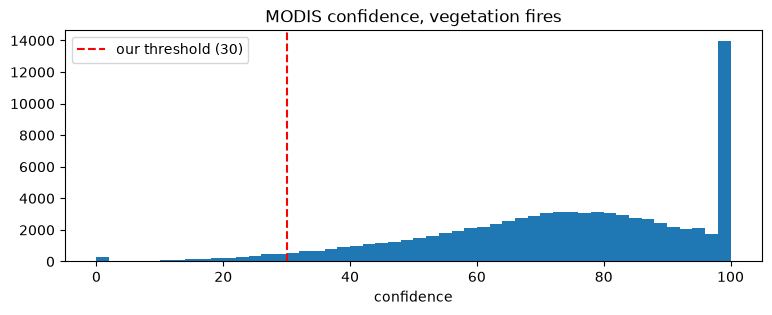

## VIIRS confidence

,rows,%
confidence,,
n,"1,268,676",90.5
l,"92,149",6.6
h,"41,591",3.0


**Share of each source type inside each VIIRS confidence level (rows sum to 100%)**

type,-1.000000,0.000000,2.000000,3.000000
confidence,,,,
h,2.7,42.9,53.4,1.0
l,2.5,32.4,65.0,0.1
n,2.0,18.5,78.9,0.6


In [8]:
from IPython.display import display, Markdown

def share_table(d, col):
    c = d[col].value_counts(dropna=False)
    return pd.DataFrame({"rows": c, "%": c / len(d) * 100})

# ---------- A. Categorical columns ----------
for s, d in raw.items():
    display(Markdown(f"## {s.upper()}: categorical columns"))
    for col in ["satellite", "instrument", "daynight", "type"]:
        if col in d.columns:
            display(Markdown(f"**{col}**"))
            display(share_table(d, col).style
                    .format({"rows": "{:,}", "%": "{:.1f}"})
                    .bar(subset=["%"], color="#5fa8d3", vmin=0, vmax=100))

# ---------- B. MODIS confidence (numeric 0-100) ----------
m = raw["modis"].copy()
m["conf"] = pd.to_numeric(m["confidence"], errors="coerce")
display(Markdown("## MODIS confidence"))
display(m["conf"].describe().round(1).to_frame("value").T)

m["bucket"] = pd.cut(m.conf, [-1, 29, 79, 100], labels=["low (<30)", "nominal (30-79)", "high (80+)"])
display(share_table(m, "bucket").style.format({"rows": "{:,}", "%": "{:.1f}"}))

# What does each possible threshold do? Measured on vegetation fires (type 0) only.
veg = m[m["type"] == 0]
rows = []
for t in [0, 10, 20, 30, 40, 50, 60, 80]:
    kept = (veg.conf >= t).sum()
    rows.append({"threshold": t, "veg. rows kept": kept, "% kept": 100 * kept / len(veg)})
display(Markdown("**Effect of the MODIS confidence threshold (vegetation fires only)**"))
display(pd.DataFrame(rows).set_index("threshold").style.format({"veg. rows kept": "{:,}", "% kept": "{:.1f}"}))

fig, ax = plt.subplots(figsize=(9, 3))
ax.hist(veg.conf, bins=50); ax.axvline(30, color="red", ls="--", label="our threshold (30)")
ax.set_title("MODIS confidence, vegetation fires"); ax.set_xlabel("confidence"); ax.legend()
plt.show()

# ---------- C. VIIRS confidence (l / n / h) ----------
v = raw["viirs"]
display(Markdown("## VIIRS confidence"))
display(share_table(v, "confidence").style.format({"rows": "{:,}", "%": "{:.1f}"}))

# How is confidence related to the source type? (each ROW sums to 100%)
display(Markdown("**Share of each source type inside each VIIRS confidence level (rows sum to 100%)**"))
display((pd.crosstab(v["confidence"], v["type"].fillna(-1), normalize="index") * 100)
        .style.format("{:.1f}").background_gradient(cmap="Blues", axis=None))

## MODIS: numeric columns

**FRP (MW) by source type** (-1 = no label)

,rows,1%,25%,50%,75%,95%,99%
type,,,,,,,
-1.000000,960,4.400000,8.600000,12.700000,19.900000,41.700000,87.700000
0.000000,"85,683",4.600000,12.300000,24.700000,55.500000,219.800000,634.400000
2.000000,"145,545",5.100000,10.900000,17.700000,30.600000,66.200000,118.900000
3.000000,175,0.000000,37.800000,66.700000,107.200000,187.000000,215.000000


**Pixel size** (scan and track in km)

,scan,track,area_km2
min,1.00,1.00,1.00
25%,1.10,1.00,1.10
median,1.30,1.10,1.43
75%,1.80,1.30,2.34
max,4.80,2.00,9.60


## VIIRS: numeric columns

**FRP (MW) by source type** (-1 = no label)

,rows,1%,25%,50%,75%,95%,99%
type,,,,,,,
-1.000000,"28,300",0.400000,1.300000,2.400000,5.400000,26.600000,94.900000
0.000000,"282,544",0.400000,1.800000,3.900000,9.200000,40.300000,115.900000
2.000000,"1,083,579",0.400000,1.200000,2.200000,4.400000,13.000000,28.700000
3.000000,"7,993",0.600000,1.700000,3.200000,6.600000,20.900000,41.800000


**Pixel size** (scan and track in km)

,scan,track,area_km2
min,0.32,0.36,0.14
25%,0.40,0.40,0.18
median,0.45,0.50,0.22
75%,0.54,0.62,0.30
max,0.80,0.78,0.62


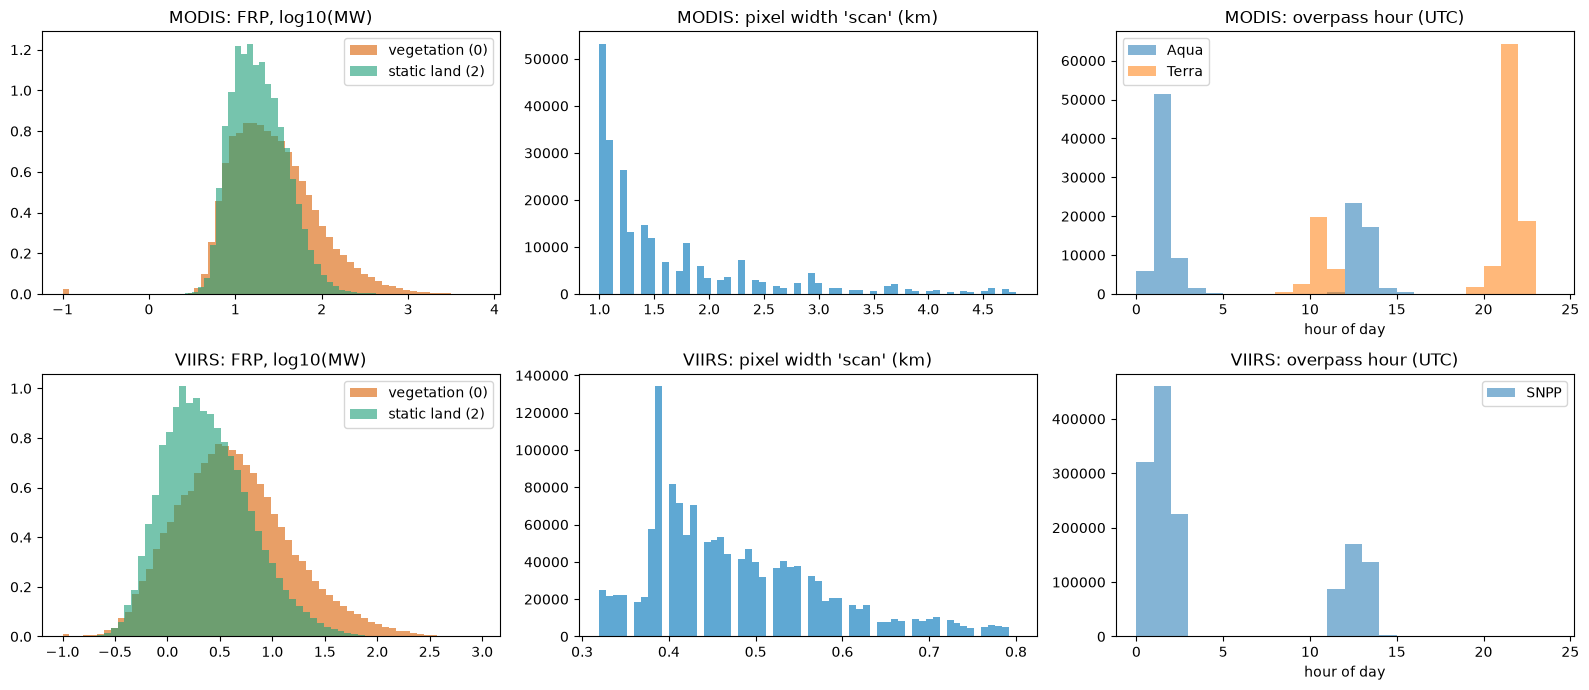

In [9]:
from IPython.display import display, Markdown

qs = [.01, .25, .5, .75, .95, .99]

# ---------- A. Tables ----------
for s, d in raw.items():
    display(Markdown(f"## {s.upper()}: numeric columns"))

    # FRP (fire power, MW) by source type: do flares and vegetation fires differ?
    frp = d.groupby(d["type"].fillna(-1))["frp"].quantile(qs).unstack().round(1)
    frp.columns = [f"{int(q*100)}%" for q in qs]
    frp.insert(0, "rows", d.groupby(d["type"].fillna(-1)).size())
    display(Markdown("**FRP (MW) by source type** (-1 = no label)"))
    display(frp.style.format({"rows": "{:,}"}))

    # Pixel size
    px = d[["scan", "track"]].copy()
    px["area_km2"] = px.scan * px.track
    display(Markdown("**Pixel size** (scan and track in km)"))
    display(px.quantile([0, .25, .5, .75, 1]).round(2)
            .rename(index={0: "min", .25: "25%", .5: "median", .75: "75%", 1: "max"}))

# ---------- B. Plots ----------
fig, ax = plt.subplots(2, 3, figsize=(16, 7))
for i, (s, d) in enumerate(raw.items()):
    # 1. FRP on a log scale, vegetation vs static sources
    for t, name, col in [(0, "vegetation (0)", "#d95f02"), (2, "static land (2)", "#1b9e77")]:
        g = d[d["type"] == t]["frp"].clip(lower=0.1)
        ax[i, 0].hist(np.log10(g), bins=60, alpha=.6, density=True, label=name, color=col)
    ax[i, 0].set_title(f"{s.upper()}: FRP, log10(MW)")
    ax[i, 0].legend()

    # 2. Pixel width
    ax[i, 1].hist(d["scan"], bins=60, color="#5fa8d3")
    ax[i, 1].set_title(f"{s.upper()}: pixel width 'scan' (km)")

    # 3. Overpass hour (UTC), one colour per satellite
    hour = d["acq_time"] // 100
    for sat, g in d.assign(hour=hour).groupby("satellite"):
        ax[i, 2].hist(g["hour"], bins=24, range=(0, 24), alpha=.55, label=str(sat))
    ax[i, 2].set_title(f"{s.upper()}: overpass hour (UTC)")
    ax[i, 2].set_xlabel("hour of day"); ax[i, 2].legend()
plt.tight_layout(); plt.show()

## MODIS: time coverage

satellite,Aqua,Terra
acq_date,,
2000,0,425
2001,0,"4,311"
2002,"2,003","4,055"
2003,"4,502","4,621"
2004,"4,297","4,459"
2005,"4,479","4,770"
2006,"5,401","5,591"
2007,"6,894","6,252"
2008,"5,320","5,587"


MODIS: 174 of 9502 days have zero detections | longest empty run: 18 days (starting 2001-06-15)


## VIIRS: time coverage

satellite,SNPP
acq_date,
2012,"70,112"
2013,"92,202"
2014,"103,447"
2015,"95,243"
2016,"101,555"
2017,"108,000"
2018,"94,711"
2019,"103,603"
2020,"102,351"


VIIRS: 59 of 5235 days have zero detections | longest empty run: 15 days (starting 2022-07-27)


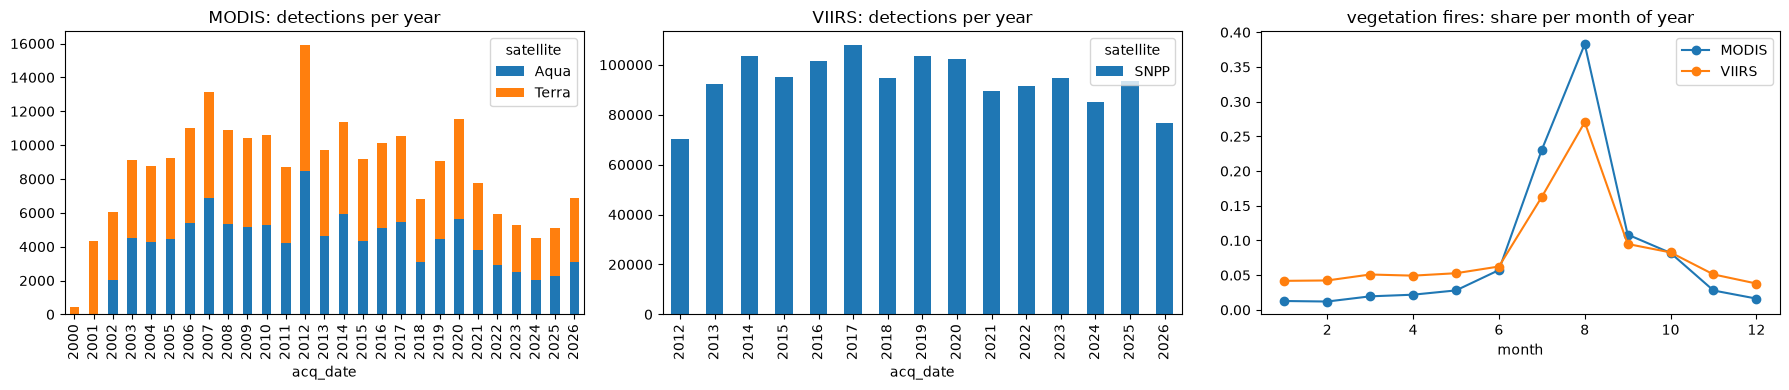

In [10]:
from IPython.display import display, Markdown

fig, ax = plt.subplots(1, 3, figsize=(18, 4))

for s, d in raw.items():
    display(Markdown(f"## {s.upper()}: time coverage"))

    # 1. Detections per year by satellite (this is also the pending 2000-2002 check)
    sat_year = d.groupby([d.acq_date.dt.year, "satellite"]).size().unstack(fill_value=0)
    display(sat_year.style.format("{:,}").background_gradient(cmap="Blues", axis=None))
    sat_year.plot(kind="bar", stacked=True, ax=ax[0 if s == "modis" else 1],
                  title=f"{s.upper()}: detections per year")

    # 2. Days with no detection at all
    daily = d.groupby("acq_date").size()
    full = pd.date_range(daily.index.min(), daily.index.max())
    missing = pd.Series(full.difference(daily.index))
    if len(missing):
        run_id = (missing.diff() != pd.Timedelta("1D")).cumsum()
        longest = run_id.value_counts().max()
        start = missing[run_id == run_id.value_counts().idxmax()].iloc[0].date()
    else:
        longest, start = 0, None
    print(f"{s.upper()}: {len(missing)} of {len(full)} days have zero detections | "
          f"longest empty run: {longest} days (starting {start})")

    # 3. Seasonality of vegetation fires: share of detections per month of year
    veg = d[d["type"] == 0]
    m = veg.groupby(veg.acq_date.dt.month).size()
    ax[2].plot(m.index, m.values / m.sum(), marker="o", label=s.upper())

ax[2].set_title("vegetation fires: share per month of year")
ax[2].set_xlabel("month"); ax[2].legend()
plt.tight_layout(); plt.show()

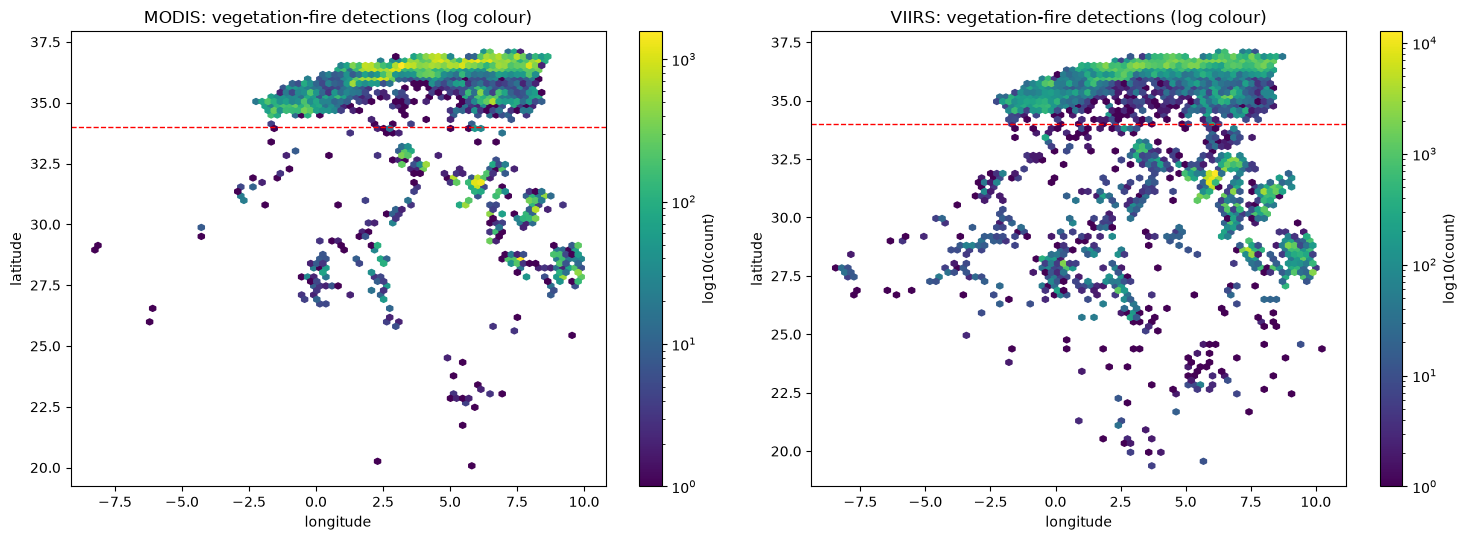

,veg. detections,north of 34N,% north of 34N,% between 33N and 34N
sensor,,,,
MODIS,"85,683","65,379",76.3,0.5
VIIRS,"282,544","139,111",49.2,0.8


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
rows = []
for a, (s, d) in zip(ax, raw.items()):
    veg = d[d["type"] == 0]
    hb = a.hexbin(veg.longitude, veg.latitude, gridsize=80, bins="log", cmap="viridis")
    a.axhline(34.0, color="red", lw=1, ls="--")
    a.set_title(f"{s.upper()}: vegetation-fire detections (log colour)")
    a.set_xlabel("longitude"); a.set_ylabel("latitude")
    fig.colorbar(hb, ax=a, label="log10(count)")

    rows.append({"sensor": s.upper(),
                 "veg. detections": len(veg),
                 "north of 34N": (veg.latitude >= 34.0).sum(),
                 "% north of 34N": 100 * (veg.latitude >= 34.0).mean(),
                 "% between 33N and 34N": 100 * veg.latitude.between(33.0, 34.0, inclusive="left").mean()})
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).set_index("sensor").style.format(
    {"veg. detections": "{:,}", "north of 34N": "{:,}", "% north of 34N": "{:.1f}", "% between 33N and 34N": "{:.1f}"}))

In [12]:
from IPython.display import display, Markdown

for s, d in raw.items():
    display(Markdown(f"## {s.upper()}"))

    # a) day/night share by source kind (each row sums to 100%)
    kind = np.where(d["type"] == 0, "vegetation", np.where(d["type"] == 2, "static land", "other/unlabelled"))
    display(Markdown("**Day / night share by source kind (%)**"))
    display((pd.crosstab(kind, d["daynight"], normalize="index") * 100).round(1))

    # b) detections per year: all types vs vegetation only
    yr = d.acq_date.dt.year
    per_year = pd.DataFrame({"all types": d.groupby(yr).size(),
                             "vegetation only": d[d["type"] == 0].groupby(yr).size()})
    display(Markdown("**Detections per year** (first and last year are partial)"))
    display(per_year.style.format("{:,.0f}").bar(color="#5fa8d3"))

    # c) top months, vegetation only
    veg = d[d["type"] == 0]
    mshare = (veg.groupby(veg.acq_date.dt.month).size() / len(veg) * 100).round(1)
    print("top months (vegetation, % of detections):", mshare.sort_values(ascending=False).head(3).to_dict())

    # d) where are the unlabelled rows?
    nl = d[d["type"].isna()]
    print(f"unlabelled: {len(nl):,} rows, {nl.acq_date.min().date()} -> {nl.acq_date.max().date()}")

## MODIS

**Day / night share by source kind (%)**

daynight,D,N
row_0,,
other/unlabelled,22.80,77.20
static land,12.60,87.40
vegetation,62.70,37.30


**Detections per year** (first and last year are partial)

,all types,vegetation only
acq_date,,
2000,425,35
2001,"4,311","1,191"
2002,"6,058","1,494"
2003,"9,123","2,720"
2004,"8,756","3,395"
2005,"9,249","3,747"
2006,"10,992","3,629"
2007,"13,146","5,491"
2008,"10,907","2,941"


top months (vegetation, % of detections): {8: 38.3, 7: 23.1, 9: 10.9}
unlabelled: 960 rows, 2026-09-01 -> 2026-11-06


... (2 outputs left out)

daynight,D,N
row_0,,
other/unlabelled,28.30,71.70
static land,22.30,77.70
vegetation,50.80,49.20


**Detections per year** (first and last year are partial)

,all types,vegetation only
acq_date,,
2012,"70,112","31,244"
2013,"92,202","16,462"
2014,"103,447","26,434"
2015,"95,243","17,021"
2016,"101,555","22,304"
2017,"108,000","26,342"
2018,"94,711","14,994"
2019,"103,603","22,008"
2020,"102,351","21,165"


top months (vegetation, % of detections): {8: 27.0, 7: 16.3, 9: 9.5}
unlabelled: 28,300 rows, 2026-08-01 -> 2026-11-02


In [13]:
from IPython.display import display, Markdown

def veg_cell_days(s, north_only=True, size=0.01):
    """Vegetation fires, same confidence rule as the pipeline, counted as occupied cell-days."""
    d = raw[s]
    conf = d["confidence"].astype(str).str.lower()
    keep = (pd.to_numeric(conf, errors="coerce") >= 30) if s == "modis" else conf.isin({"n", "h"})
    d = d[keep & (d["type"] == 0)]
    if north_only:
        d = d[d.latitude >= 34.0]
    d = d.assign(clat=(d.latitude / size).round().astype(int),
                 clon=(d.longitude / size).round().astype(int))
    return d.drop_duplicates(subset=["clat", "clon", "acq_date"])

# 1. Is the MODIS/VIIRS relationship stable over the years?
yearly = {}
for s in ["modis", "viirs"]:
    d = veg_cell_days(s)
    yearly[s.upper()] = d.groupby(d.acq_date.dt.year).size()
tab = pd.DataFrame(yearly).loc[2003:2025]
tab["VIIRS/MODIS"] = tab["VIIRS"] / tab["MODIS"]
display(Markdown("**Vegetation cell-days per year, north of 34N** (VIIRS starts mid-2012, so 2012 is partial)"))
display(tab.style.format({"MODIS": "{:,.0f}", "VIIRS": "{:,.0f}", "VIIRS/MODIS": "{:.2f}"}))

# 2. Do the overpass times drift? (day passes only, median UTC hour)
times = []
for s in ["modis", "viirs"]:
    d = raw[s]
    d = d[d["daynight"] == "D"]
    hour = d["acq_time"] // 100 + (d["acq_time"] % 100) / 60
    times.append(hour.groupby([d.acq_date.dt.year, d["satellite"]]).median().unstack())
display(Markdown("**Median day-pass hour (UTC), by year**"))
display(pd.concat(times, axis=1).style.format("{:.2f}"))

# 3. Months with outages (3+ days with zero detections of any type)
for s, d in raw.items():
    days = pd.DatetimeIndex(d["acq_date"].unique()).sort_values()
    empty = pd.date_range(days.min(), days.max()).difference(days)
    per_month = pd.Series(1, index=empty).groupby(empty.to_period("M")).sum()
    bad = per_month[per_month >= 3]
    print(f"{s.upper()}: {len(bad)} months with 3+ empty days ->", {str(k): int(v) for k, v in bad.items()})

**Vegetation cell-days per year, north of 34N** (VIIRS starts mid-2012, so 2012 is partial)

,MODIS,VIIRS,VIIRS/MODIS
acq_date,,,
2003,"1,694",nan,nan
2004,"2,202",nan,nan
2005,"2,715",nan,nan
2006,"2,416",nan,nan
2007,"4,257",nan,nan
2008,"2,116",nan,nan
2009,"2,836",nan,nan
2010,"2,633",nan,nan
2011,"1,850",nan,nan


**Median day-pass hour (UTC), by year**

satellite,Aqua,Terra,SNPP
acq_date,,,
2000,nan,10.93,nan
2001,nan,10.88,nan
2002,12.83,10.63,nan
2003,12.80,10.70,nan
2004,12.83,10.70,nan
2005,12.90,10.60,nan
2006,12.83,10.60,nan
2007,12.85,10.62,nan
2008,12.77,10.70,nan


MODIS: 13 months with 3+ empty days -> {'2000-12': 5, '2001-06': 16, '2001-12': 3, '2002-01': 3, '2002-02': 3, '2002-03': 12, '2017-12': 3, '2018-10': 3, '2022-04': 4, '2024-01': 7, '2024-02': 5, '2025-12': 3, '2026-01': 6}
VIIRS: 8 months with 3+ empty days -> {'2022-07': 5, '2022-08': 10, '2024-06': 3, '2024-07': 12, '2024-11': 4, '2026-03': 3, '2026-04': 3, '2026-07': 6}


In [14]:
from IPython.display import display, Markdown

mon = {}
for s in ["modis", "viirs"]:
    d = veg_cell_days(s)                       # north of 34N, vegetation, same filters as before
    mon[s] = d.groupby(d.acq_date.dt.to_period("M")).size()
m = pd.DataFrame(mon).dropna()

outages = ["2017-12", "2018-10", "2022-04", "2022-07", "2022-08", "2024-01", "2024-02",
           "2024-06", "2024-07", "2024-11", "2025-12", "2026-01", "2026-03", "2026-04", "2026-07"]
m = m[(m.index >= pd.Period("2013-01")) & (m.index <= pd.Period("2026-07"))]
m = m.drop(index=[pd.Period(x) for x in outages if pd.Period(x) in m.index])
m = m[(m.modis >= 5) & (m.viirs >= 5)]        # tiny counts are mostly noise
m["lm"], m["lv"] = np.log(m.modis), np.log(m.viirs)

early = m[m.index <= pd.Period("2021-12")]
late = m[m.index >= pd.Period("2022-01")]

fits = {}
for name, df in [("2013-2021", early), ("2022-2026", late)]:
    b, a = np.polyfit(df.lm, df.lv, 1)
    fits[name] = {"months": len(df), "slope b": round(b, 2), "intercept a": round(a, 2)}
display(Markdown("**Log-log fit by period**"))
display(pd.DataFrame(fits).T)

b, a = np.polyfit(early.lm, early.lv, 1)
res = late.lv - (a + b * late.lm)
sd = (early.lv - (a + b * early.lm)).std()
print(f"2013-2021 line applied to 2022-2026: mean residual {res.mean():+.2f} "
      f"({np.expm1(res.mean()) * 100:+.0f}% in VIIRS terms); normal monthly scatter = {sd:.2f}")
by_year = res.groupby(res.index.year).agg(["mean", "size"]).round(2)
by_year.columns = ["mean residual", "months"]
display(Markdown("**Residual by year** (negative = MODIS sees more than expected for that VIIRS)"))
display(by_year)

**Log-log fit by period**

,months,slope b,intercept a
2013-2021,99.00,0.68,2.78
2022-2026,41.00,0.55,3.21


2013-2021 line applied to 2022-2026: mean residual -0.04 (-3% in VIIRS terms); normal monthly scatter = 0.25


**Residual by year** (negative = MODIS sees more than expected for that VIIRS)

,mean residual,months
acq_date,,
2022,0.12,8
2023,-0.04,12
2024,-0.11,7
2025,-0.01,11
2026,-0.33,3


In [15]:
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

OVERLAP_START = pd.Timestamp("2013-01-01")
LAST_FULL_MONTH = pd.Timestamp("2026-10-01")
FIRST_RELIABLE = pd.Timestamp("2003-01-01")
PROC = Path("../data/processed")

# months with 3+ empty days in the raw Algeria files, either sensor (from the outage check)
OUTAGE_MONTHS = {"algeria": ["2017-12", "2018-10", "2022-04", "2022-07", "2022-08", "2024-01", "2024-02",
                             "2024-06", "2024-07", "2024-11", "2025-12", "2026-01", "2026-03", "2026-04", "2026-07"]}

def monthly_total(g):
    s = g.groupby(["year", "month"])["count"].sum()
    s.index = pd.to_datetime(dict(year=s.index.get_level_values(0), month=s.index.get_level_values(1), day=1))
    return s

def with_date(g):
    return g.assign(date=pd.to_datetime(dict(year=g.year, month=g.month, day=1)))

def fit_loglog_smear(t):
    x, y = np.log(t.modis + 1), np.log(t.viirs + 1)
    b, a = np.polyfit(x, y, 1)
    return b, a, np.mean(np.exp(y - (a + b * x)))

def pred_loglog_smear(p, m):
    b, a, smear = p
    return smear * np.exp(a + b * np.log(m + 1)) - 1

summary, yearly = [], {}
for region in ["algeria", "portugal", "zambia"]:
    bad = list(pd.to_datetime([m + "-01" for m in OUTAGE_MONTHS.get(region, [])]))
    gm = pd.read_parquet(PROC / f"{region}_grid_m.parquet")
    gv = pd.read_parquet(PROC / f"{region}_grid_v.parquet")
    mt = monthly_total(gm)

    # 1. calibration table: months where both sensors exist, outage months removed
    both = pd.concat([mt.rename("modis"), monthly_total(gv).rename("viirs")], axis=1, sort=True).dropna()
    both = both[(both.index >= OVERLAP_START) & (both.index <= LAST_FULL_MONTH)]
    fit = both[~both.index.isin(bad)]
    p_all = fit_loglog_smear(fit)

    # 2. sensitivity: how much would the reconstructed 2003-2012 total change with a 2013-2021-only fit?
    p_early = fit_loglog_smear(fit[fit.index <= "2021-12-31"])
    pre = mt[(mt.index >= FIRST_RELIABLE) & (mt.index < OVERLAP_START)]
    window_diff = pred_loglog_smear(p_early, pre).sum() / pred_loglog_smear(p_all, pre).sum() - 1

    # 3. leave-one-year-out: each year is predicted by a model that never saw it
    errs = []
    for y in sorted(set(fit.index.year)):
        tr, te = fit[fit.index.year != y], fit[fit.index.year == y]
        errs.append(pd.DataFrame({"obs": te.viirs, "pred": pred_loglog_smear(fit_loglog_smear(tr), te.modis)}))
    cv = pd.concat(errs)
    cv = cv[cv.obs > 0]
    rel = (cv.obs - cv.pred).abs() / cv.obs

    # 4. harmonized series: MODIS cells before 2013 (rescaled), VIIRS cells from 2013
    g = with_date(gm)
    g = g[g.date < OVERLAP_START].copy()
    tot = g.groupby("date")["count"].transform("sum")
    g["count"] = g["count"] / tot * pred_loglog_smear(p_all, tot)
    g["source"], g["reliable"] = "MODIS (calibrated)", g.date >= FIRST_RELIABLE
    v = with_date(gv)
    v = v[(v.date >= OVERLAP_START) & (v.date <= LAST_FULL_MONTH)].copy()
    v["source"], v["reliable"] = "VIIRS", True

    h = pd.concat([g, v], ignore_index=True)
    h["outage"] = h.date.isin(bad)
    h = h[["lat", "lon", "year", "month", "count", "source", "reliable", "outage"]]
    h.to_parquet(PROC / f"{region}_monthly_grid.parquet", index=False)

    # 5. sanity checks
    gap = (g.groupby("date")["count"].sum() - pred_loglog_smear(p_all, mt[mt.index < OVERLAP_START])).abs().max()
    r = h[h.reliable]
    yearly[region] = r.groupby("year")["count"].sum()
    peaks = {}
    for name, d in [("2003-12", r[r.year < 2013]), ("2013-26", r[r.year >= 2013])]:
        s = d.groupby("month")["count"].sum()
        peaks[name] = f"{int(s.idxmax())} ({s.max() / s.sum():.0%})"
    summary.append({"region": region, "fit months": len(fit), "b / a / smear": f"{p_all[0]:.2f} / {p_all[1]:.2f} / {p_all[2]:.2f}",
                    "held-out median err": f"{rel.median():.1%}",
                    "held-out total bias": f"{cv.pred.sum() / cv.obs.sum() - 1:+.1%}",
                    "2013-21 fit vs all, pre-2013 total": f"{window_diff:+.1%}",
                    "peak month 2003-12": peaks["2003-12"], "peak month 2013-26": peaks["2013-26"],
                    "max |cells sum - model|": f"{gap:.1e}"})

display(pd.DataFrame(summary).set_index("region").T)
display(pd.DataFrame(yearly).style.format("{:,.0f}", na_rep="-"))

region,algeria,portugal,zambia
fit months,151,163,166
b / a / smear,0.66 / 2.83 / 1.04,0.82 / 1.44 / 1.06,0.89 / 2.10 / 1.04
held-out median err,16.0%,21.3%,14.1%
held-out total bias,-3.3%,+0.9%,+2.8%
"2013-21 fit vs all, pre-2013 total",+4.6%,+8.8%,+1.0%
peak month 2003-12,8 (35%),8 (31%),8 (26%)
peak month 2013-26,8 (34%),8 (31%),8 (30%)
max |cells sum - model|,5.7e-14,5.7e-14,1.1e-13


,algeria,portugal,zambia
year,,,
2003,"3,898","6,374","493,934"
2004,"5,045","4,006","475,351"
2005,"5,962","8,987","530,492"
2006,"5,537","3,189","456,625"
2007,"6,666","2,356","504,830"
2008,"4,738","1,781","535,546"
2009,"5,593","4,377","476,959"
2010,"5,894","4,582","522,967"
2011,"4,415","3,930","519,408"
